# 06-ROS2语音、大模型与MCP机器人控制


## 1. 课程主线与资料范围

本篇对应《ROS语音&AI与控制.pdf》，在前面视觉、通信与运动控制的基础上，为机器人加入语音输入、语言理解和工具调用能力。

课件共41页，已逐页核对PDF页面预览。第1—40页包含封面、目录、章节页与教学内容，第41页为品牌结束页。按原课顺序分成四部分：语音的听和说、大语言模型、MCP服务、ROS集成。

本篇保留课件的录音参数、Whisper与TTS例子、DeepSeek调用方式、MCP算术与机械臂案例，以及最后的MCP-to-Topic架构。图片标注原页码。完整示例和接口差异说明属于明确标记的**工程补充**，不是视频或课程源码压缩包的转录。

前置环境沿用Ubuntu 24.04与ROS2 Jazzy。以下命令用于Ubuntu；Notebook只有Markdown阅读单元。语音、模型与MCP先独立验证，最后再加载ROS环境。未在麦克风、扬声器、云模型API、ROS2或真实机械臂上实跑；本地MCP验证结果在末节单独说明。


## 2. 从语音界面到完整交互链

课件第4—6页说明机器人为什么需要“能听会说”：语音界面VUI可以在用户不便接触键盘、屏幕时提供自然交互。它需要多个模块协作，不是一个语音识别模型就能完成全部任务。

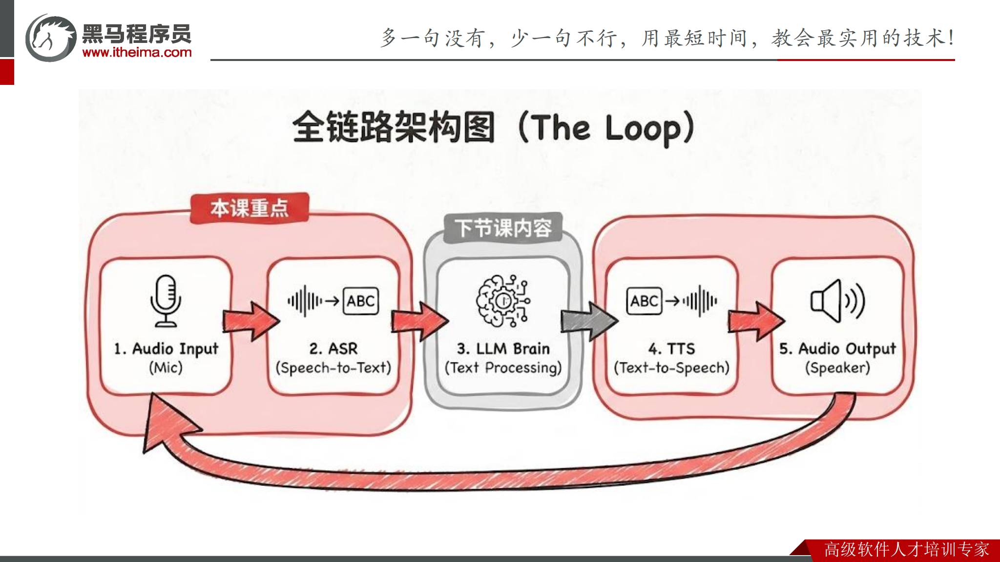

*原课件第6页：采集声音、识别文本、处理文本、合成语音、播放声音。*

| 模块 | 输入与输出 | 负责的问题 |
|---|---|---|
| 麦克风采集 | 声音 → 音频数据 | 获取正确设备与音频格式 |
| VAD，语音活动检测 | 音频 → 说话区间 | 当前是否有人说话、何时结束 |
| ASR，自动语音识别 | 音频 → 文本 | 用户说了什么 |
| LLM，大语言模型 | 文本与上下文 → 回答或工具调用 | 如何理解和回应 |
| TTS，文本转语音 | 文本 → 合成音频 | 如何把文字读出来 |
| 播放器与扬声器 | 音频 → 声音 | 实际输出声音 |

第6页先练习输入与输出，随后才加入LLM。开发时也按这个顺序：先确认录音能播放、文字能识别、TTS能发声，再接入对话和控制。

**工程补充：**固定录5秒不等于已实现VAD；ASR输出文本也不等于用户意图已经明确。播报时若麦克风把机器人自己的声音重新录进去，还可能形成自问自答，需要安排录音与播放时序或处理回声。


## 3. 声音数字化：采样率、位深与声道

课件第7—8页介绍ADC，即模数转换：在时间上采样，在幅值上量化，得到可存储和处理的数字音频。

| 参数 | 本课录音值 | 含义 |
|---|---:|---|
| 采样率，RATE | 16000 Hz | 每秒每声道采集16000个样本 |
| 采样格式，FORMAT | `pyaudio.paInt16` | 每个样本用16位有符号整数表示 |
| 声道数，CHANNELS | 1 | 单声道 |
| 块大小，CHUNK | 1024 | 每次读取1024帧音频 |
| 时长 | 5秒 | 固定长度的教学录音 |
| 文件名 | `output.wav` | 保存采集结果 |

对于未压缩PCM音频：

\[
\text{数据率(bit/s)}=\text{采样率}\times\text{位深}\times\text{声道数}.
\]

本例为`16000 × 16 × 1 = 256000 bit/s`，即每秒32000字节。5秒音频样本占160000字节，WAV文件还包括文件头等信息。课件“数据量”公式省略了时长，严格说右边先得到数据率。

一帧包含各声道在同一时刻的样本。单声道时一帧一个样本；双声道时不能仍按一个样本计算大小。`CHUNK=1024`不是采样率，也不是录音总长度，本例每块约为64毫秒。

采样率、通道数与格式需要采集设备支持。更改WAV头不能把44.1kHz的音频真正变成16kHz；格式不匹配时需要实际重采样。


## 4. PyAudio录音与环境准备

课件第8页给出`01_recording_demo.py`的核心参数，第9页说明PyAudio依赖PortAudio，不能只把导入错误理解为Python语法问题。

以下为**工程补充**，沿用项目的uv习惯。在Ubuntu先准备独立实验环境：

```bash
sudo apt update
sudo apt install portaudio19-dev python3-dev build-essential ffmpeg
mkdir -p ~/ai_robot_lab
cd ~/ai_robot_lab
uv venv --python 3.12
uv pip install --python .venv/bin/python pyaudio
.venv/bin/python -c 'import pyaudio; print(pyaudio.get_portaudio_version_text())'
```

导入成功只说明库可用，还需在Ubuntu声音设置中选中实际输入设备。虚拟机使用麦克风时，应确认音频输入确实转交给虚拟机。

保存`~/ai_robot_lab/01_recording_demo.py`：

```python
import wave
import pyaudio

CHUNK = 1024
FORMAT = pyaudio.paInt16
CHANNELS = 1
RATE = 16000
RECORD_SECONDS = 5
WAVE_OUTPUT_FILENAME = 'output.wav'


def main():
    audio = pyaudio.PyAudio()
    stream = None
    frames = []
    try:
        sample_width = audio.get_sample_size(FORMAT)
        stream = audio.open(
            format=FORMAT, channels=CHANNELS, rate=RATE,
            input=True, frames_per_buffer=CHUNK)
        remaining = RATE * RECORD_SECONDS
        while remaining > 0:
            count = min(CHUNK, remaining)
            frames.append(stream.read(count))
            remaining -= count
    finally:
        if stream is not None:
            stream.stop_stream()
            stream.close()
        audio.terminate()

    with wave.open(WAVE_OUTPUT_FILENAME, 'wb') as output:
        output.setnchannels(CHANNELS)
        output.setsampwidth(sample_width)
        output.setframerate(RATE)
        output.writeframes(b''.join(frames))
    print(f'Saved {WAVE_OUTPUT_FILENAME}')


if __name__ == '__main__':
    main()
```

在实验目录运行并回听：

```bash
cd ~/ai_robot_lab
.venv/bin/python 01_recording_demo.py
ffplay -nodisp -autoexit output.wav
```

预期文件含5秒、16kHz、16位、单声道PCM数据，能听清自己的声音。代码最后一块按剩余帧数读取，避免整除截断使时长不足5秒；设备打开或读取失败时释放资源并报告异常。

课件第9页另提到Windows的wheel安装和Conda；实际安装包需匹配Python版本与系统架构。本篇继续使用Ubuntu与uv，不把来源不明的wheel作为通用修复。


## 5. ASR与Whisper：从音频得到文字

课件第10页用声谱图解释语音识别：把声音表示成随时间变化的频率特征，再交给模型得到文本。“看到声音的图像”是直觉类比，不表示所有ASR系统都采用完全相同的输入与网络。

第11页比较在线与本地方案：在线服务依赖网络和服务端；本地模型可在准备好依赖、权重后离线运行，但需要本机算力。课件列举的价格与性能是场景示意，实际以服务、模型与硬件为准。

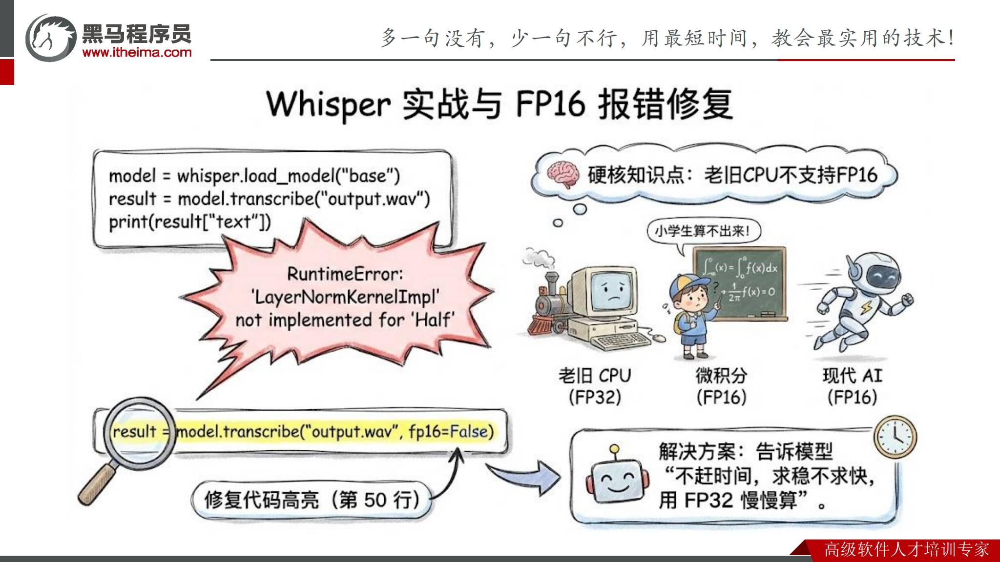

*原课件第12页：在CPU环境中使用FP32，显式设置fp16=False。*

在前面的独立环境安装开源Whisper，包名是`openai-whisper`，导入名为`whisper`：

```bash
cd ~/ai_robot_lab
uv pip install --python .venv/bin/python openai-whisper
```

保存`02_asr_demo.py`，使用第4节的录音文件：

```python
import whisper

model = whisper.load_model('base', device='cpu')
result = model.transcribe('output.wav', fp16=False, language='zh')
print(result['text'].strip())
```

```bash
.venv/bin/python 02_asr_demo.py
```

预期得到录音的文字转写，标点与措辞可能和人工记录不同。首次加载模型通常需要下载权重，音频解码还依赖FFmpeg；“本地推理”不等于首次运行完全不联网。

**工程澄清：**课件将Half报错概括为“老旧CPU不支持FP16”。此处关键是所用PyTorch算子、设备与精度组合是否受支持。示例明确用CPU与`fp16=False`，不需要据此判断所有CPU硬件能力。

静音、背景噪声、距离与语言配置会影响结果。先回听原音频，确认录音正确，再排查识别模型；不要把识别出的任意文字直接当成已确认的运动指令。


## 6. TTS：离线播报与在线合成

课件第13页按拼接合成、统计参数合成、神经合成说明TTS技术的变化，第14页分别展示`pyttsx3`和`edge_tts`。

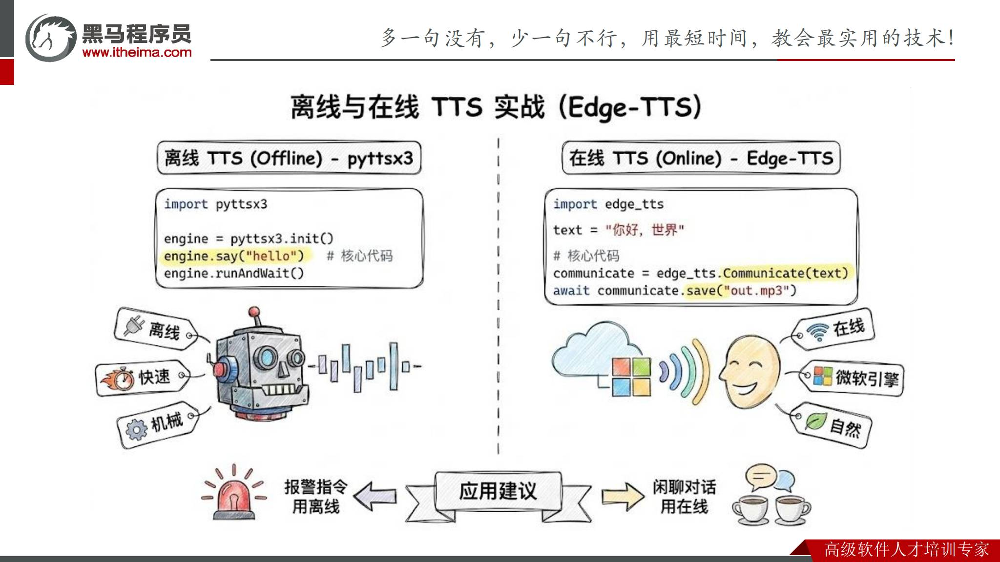

*原课件第14页：pyttsx3调用本地语音引擎；Edge-TTS连接在线服务。*

先为独立环境安装Python依赖；Ubuntu本地引擎示例另需eSpeak相关系统组件：

```bash
sudo apt install espeak-ng libespeak1
cd ~/ai_robot_lab
uv pip install --python .venv/bin/python pyttsx3 edge-tts
```

离线示例保存为`03_tts_local.py`：

```python
import pyttsx3

engine = pyttsx3.init()
try:
    engine.say('Hello, robot.')
    engine.runAndWait()
finally:
    engine.stop()
```

运行`.venv/bin/python 03_tts_local.py`，预期扬声器播报英文。中文质量与可用音色取决于系统引擎和语音包，`pyttsx3`本身不提供一套统一的神经语音模型。

在线示例保存为`04_tts_online.py`，在课件片段上补齐异步入口与音色：

```python
import asyncio
import edge_tts


async def main():
    speech = edge_tts.Communicate(
        '你好，机器人。', voice='zh-CN-XiaoxiaoNeural')
    await speech.save('out.mp3')


if __name__ == '__main__':
    asyncio.run(main())
```

```bash
.venv/bin/python 04_tts_online.py
ffplay -nodisp -autoexit out.mp3
```

保存MP3和播放声音是两个步骤。`edge_tts`需要网络，可用音色与服务行为应以实际版本为准；“本地安装Python库”不表示合成也在本地完成。

课件建议报警等固定提示优先考虑离线可用，闲聊可使用在线音色。先分别验证两种输出，再把LLM回答交给TTS，避免同时排查模型、网络和播放设备。


## 7. 从规则匹配到大语言模型

课件第15—17页从传统“关键词/规则匹配”转到大语言模型：规则程序需要事先枚举表达，语言模型可以根据上下文处理更灵活的说法。

例如“把夹爪打开”和“松开手”可能指向同一个工具，但字符串并不相同。LLM的作用是把表达和上下文映射到适当回答或结构化调用；它没有因此自动获得硬件接口。

**工程澄清：**课件将传统智能音箱概括为规则匹配，是为对比教学而作的简化，不能据此断言所有传统产品只有规则。模型也可能误解上下文或生成不正确内容，不能把“会说”直接等同于“会可靠执行”。

机器人系统要保留分工：ASR输出文本，LLM处理语言，确定性程序检查并执行接口，执行状态再回到对话中。后面MCP与ROS集成正是围绕这条分工展开。


## 8. Embedding：用数字表示语义关系

课件第18—19页用二维词向量解释Embedding：将词或token表示为数值向量，使语言关系可以进入数值计算。

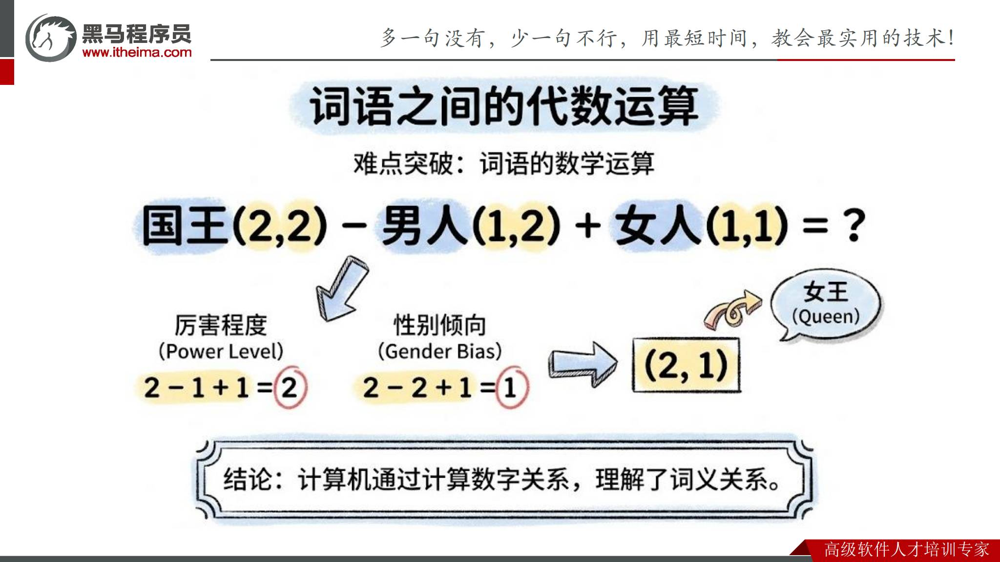

*原课件第19页：用“国王－男人＋女人”的二维算式帮助理解向量关系。*

课件设定`国王=(2,2)`、`男人=(1,2)`、`女人=(1,1)`，于是：

\[
(2,2)-(1,2)+(1,1)=(2,1),
\]

在这组教学坐标里对应“女王”。它说明向量可以表达关系，不是实际训练出的测量数据。

**工程澄清：**真实Embedding通常有很多维，维度不是人工命名的“厉害程度”“性别”等固定轴；向量类比也不是所有词都严格满足的代数定律。现代语言模型处理token并结合上下文，词的表示会比这张静态二维表复杂。

需要记住的是“语言可表示为向量并参与计算”，无需把这组二维数值当成模型内部结构。


## 9. 下一token预测、自回归与流式输出

课件第20—21页解释生成过程：模型根据已有上下文计算接下来可能出现的token，再把生成结果放进上下文继续生成，这称为自回归。

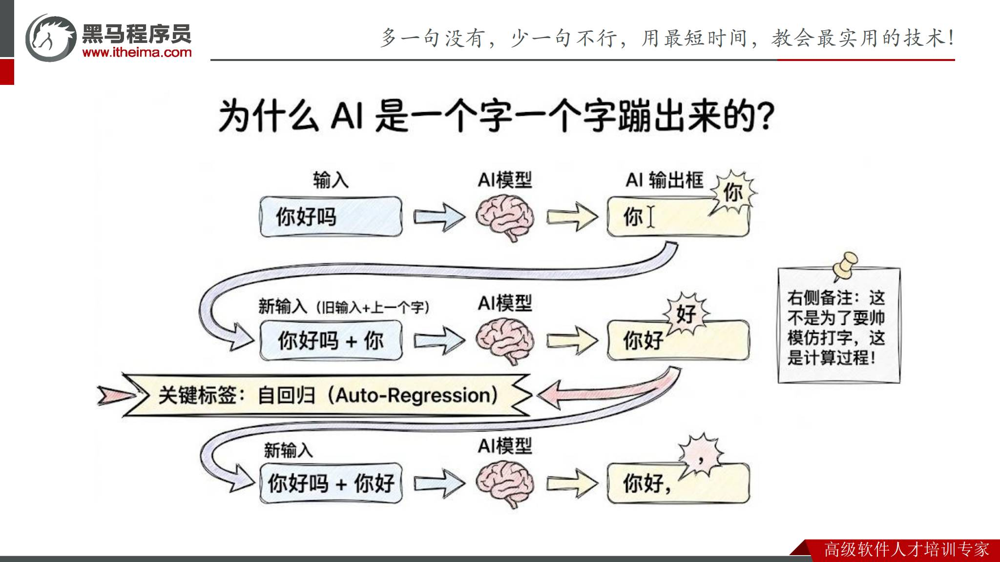

*原课件第21页：已生成的部分参与下一步预测。*

token可能是一个字、一个词、词的一部分或符号，因此课件“一个字一个字输出”是易懂的表述，不能据此按字符估算所有模型的token数。

第20页的“晴朗85%、不错70%”是候选倾向的示意，不是一组经过归一化、可以直接相加的互斥概率。模型的下一个token分布也不等于回答事实正确的概率。

**工程补充：**模型逐步生成与接口是否流式返回是两件事。`stream=False`时调用者通常等完整响应；启用流式传输后才能逐步接收增量，但网络块也不保证恰好一个字或一个token。

接入TTS时，不能把每个到达的小字符串都独立合成为一段声音；需要按可播放片段组织，兼顾等待时间与语句完整性。本课先使用完整文本响应来理解流程。


## 10. 大模型API：地址、凭据与请求内容

课件第22页把API比作服务员：Python程序按约定发送请求，服务端运行模型，再返回结果。第23页列出地址、API Key和Payload三个要素。

| 要素 | 在本课中的作用 |
|---|---|
| Base URL | 请求发送到哪家服务商的接口 |
| API Key | 服务商发放的访问凭据 |
| model | 使用哪个模型标识 |
| messages / Prompt | 对话角色、上下文与本次问题 |

第24页使用OpenAI Python SDK访问DeepSeek兼容接口：`from openai import OpenAI`说明使用哪个客户端库，不表示请求一定发送给OpenAI。

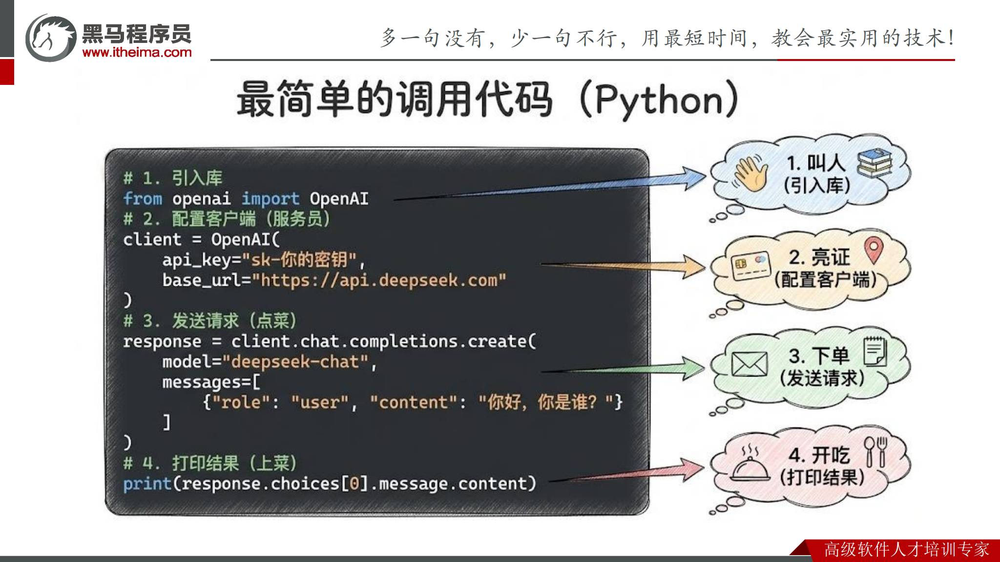

*原课件第24页：配置DeepSeek地址与模型，通过Chat Completions读取文本结果；图中密钥是占位符。*

以下在`~/ai_robot_lab/`安装固定的示例SDK版本，并从环境读取凭据：

```bash
uv pip install --python .venv/bin/python openai==2.54.0
read -r -s -p 'DeepSeek API key: ' DEEPSEEK_API_KEY
export DEEPSEEK_API_KEY
printf '\n'
```

保存`05_llm_demo.py`：

```python
import os
from openai import OpenAI

with OpenAI(
    api_key=os.environ['DEEPSEEK_API_KEY'],
    base_url='https://api.deepseek.com',
    timeout=30.0,
) as client:
    response = client.chat.completions.create(
        model=os.environ.get('LLM_MODEL', 'deepseek-chat'),
        messages=[{'role': 'user', 'content': '你好，你是谁？'}],
    )
    print(response.choices[0].message.content or '')
```

```bash
.venv/bin/python 05_llm_demo.py
```

本篇保留课件的`deepseek-chat`模型名作为默认值，**不保证这个课程时期的标识在实际运行时仍可用**。运行前核对服务商当前文档与账号可用模型；如需调整，通过`LLM_MODEL`显式配置。请求格式兼容也不表示所有模型能力与参数完全相同。

本段补充参考[OpenAI Python SDK官方文档](https://developers.openai.com/api/reference/python)与[DeepSeek首次调用文档](https://api-docs.deepseek.com/)。这里按原课保留Chat Completions调用，不把服务商接口换成另一套API。密钥不写进Notebook或源码，模型调用错误也不能当成有效回答传给后续控制模块。


## 11. MCP解决什么问题

课件第25—28页引入MCP，即Model Context Protocol，模型上下文协议。模型本身不会直接读取编码器、开关夹爪或查询某个业务数据库，需要应用程序为它连接这些外部能力。

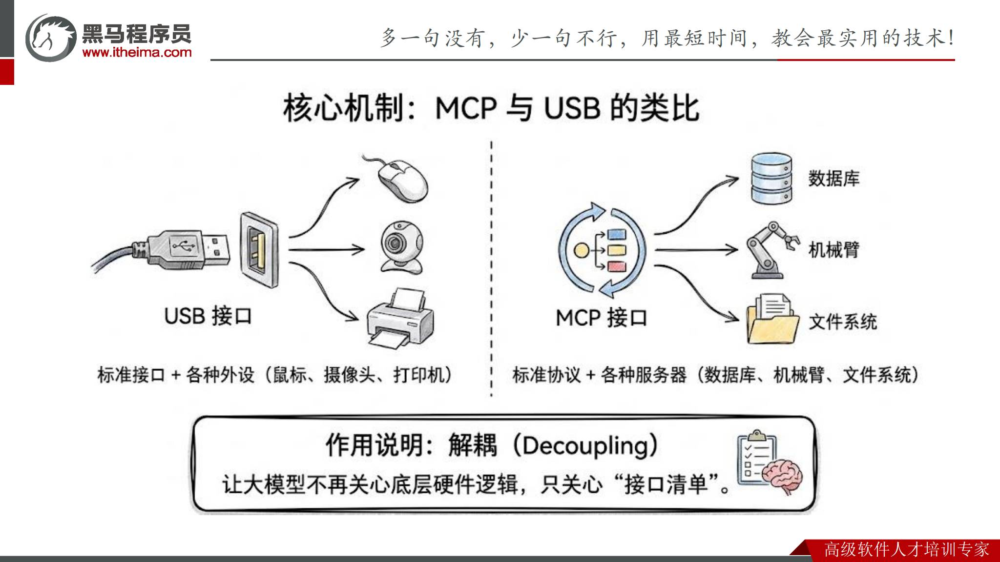

*原课件第28页：用USB接口类比MCP，让调用方围绕统一接口连接不同能力。*

MCP提供工具发现与调用等标准交互方式。对于本课，工具可以先是`add()`，再换成`rotate_waist()`或`control_gripper()`。具体串口、SDK或ROS调用依然由工具实现。

| 角色 | 本课中承担的职责 |
|---|---|
| Host / 应用程序 | 组织模型对话、工具目录、调用策略与结果回传 |
| MCP Client | 连接服务器，发现工具，发送调用请求 |
| MCP Server | 描述并提供工具，检查参数，执行后端逻辑 |
| LLM | 根据上下文选择回答或请求调用某个工具 |

**工程澄清：**课件把Client直接标为“大模型/决策者”，是体系图的简写；实际是运行模型的应用持有Client，模型不会仅靠一个普通文本请求自动连接任意MCP Server。MCP也不是电机控制协议或硬实时控制器。

第27页提醒不要凭模型记忆推断协议细节。客户端库、传输方式和版本都需核对。下文补充示例固定使用`fastmcp==2.14.7`，不会把其他主版本的接口混进同一段代码。


## 12. 第一个MCP Server：创建、注册、启动

课件第29页给出三个步骤：创建`FastMCP`实例，通过`@mcp.tool()`注册函数，再运行服务。第30页要求在基础Demo上增加乘法工具。

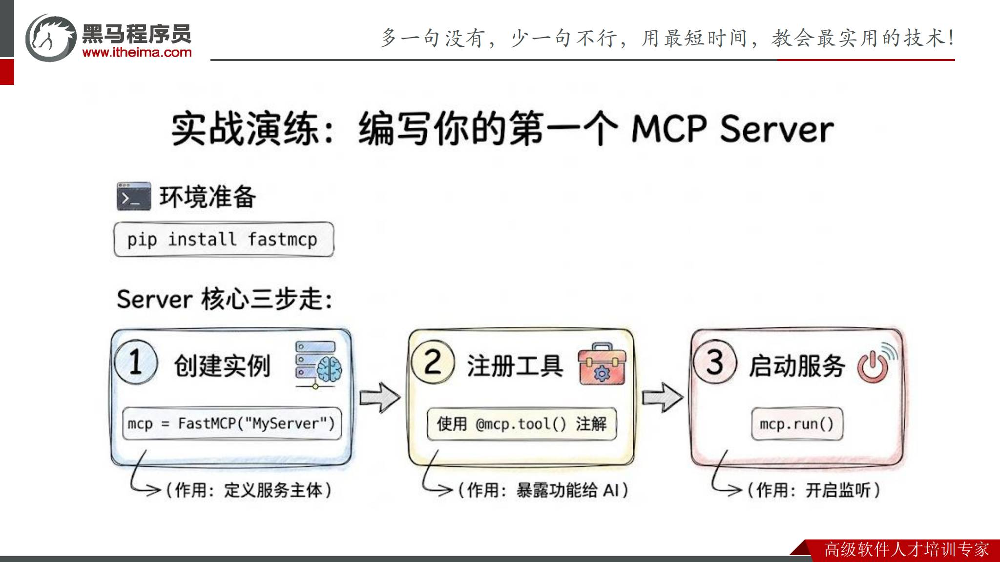

*原课件第29页：实例、工具与服务入口。*

在独立实验环境安装：

```bash
cd ~/ai_robot_lab
uv pip install --python .venv/bin/python fastmcp==2.14.7
```

保存`server.py`，以下为**工程补充完整示例**：

```python
from fastmcp import FastMCP

mcp = FastMCP('MyServer')


@mcp.tool()
def add(a: int, b: int) -> int:
    """返回两个整数的和。"""
    return a + b


@mcp.tool()
def multiply(a: int, b: int) -> int:
    """返回两个整数的乘积。"""
    return a * b


if __name__ == '__main__':
    mcp.run(transport='http', host='127.0.0.1', port=8000)
```

```bash
.venv/bin/python server.py
```

服务保持运行。函数名、说明文档与类型标注共同帮助描述工具；`@mcp.tool()`只注册能力，不代表已经有模型来调用它。

**课件差异说明：**第29页只写`mcp.run()`，第31页却展示两个终端通过`127.0.0.1:8000`连接。在本篇固定的FastMCP版本中，应显式选择HTTP传输，对应默认MCP路径`/mcp`。默认stdio模式使用标准输入输出通信，不能当成已监听8000端口。

此处`127.0.0.1`表示同一台机器；将Client迁到其他机器时，不能继续用它指代服务器。课件第32页的分布式示意还需要真实的网络部署条件，不是改一句Client名称就完成。


## 13. MCP Client：连接、发现工具、调用、读取结果

课件第31—34页强调观察连接与工具发现。先不接LLM，直接验证Client是否能调用Server，缩小调试范围。

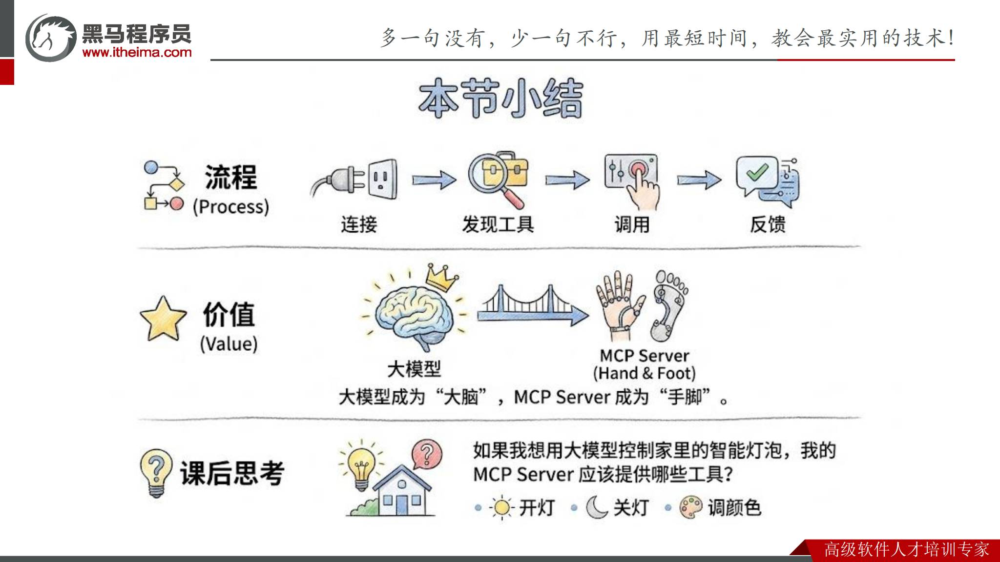

*原课件第34页：连接 → 发现工具 → 调用 → 反馈。*

保存`~/ai_robot_lab/client.py`，另开终端运行：

```python
import asyncio
from fastmcp import Client


async def main():
    async with Client('http://127.0.0.1:8000/mcp') as client:
        tools = await client.list_tools()
        for tool in tools:
            print(tool.name, tool.description, tool.inputSchema)
        result = await client.call_tool('add', {'a': 4, 'b': 5})
        print('add:', result.data)
        result = await client.call_tool('multiply', {'a': 4, 'b': 5})
        print('multiply:', result.data)


if __name__ == '__main__':
    asyncio.run(main())
```

```bash
cd ~/ai_robot_lab
.venv/bin/python client.py
```

预期能发现`add`和`multiply`，调用分别得到9和20。`inputSchema`是本篇固定版本返回的MCP工具字段；新主版本的包装接口可能不同。

工具发现得到“有哪些能力、每个能力需要什么参数”，不是执行了全部工具。调用结果也应读取实际返回数据；连接成功不能当成业务成功。FastMCP Client在默认配置下会把工具执行错误抛为异常。

第30页的提高题是读取本地磁盘剩余空间，可将`shutil.disk_usage()`的只读结果封装成工具；拓展题是为智能灯定义开、关、调色接口。第33页继续把同样模式用于机械臂。核心都是先写清接口，再实现其背后的设备操作。

补充接口用法参照[FastMCP服务运行文档](https://gofastmcp.com/deployment/running-server)与[Client工具调用文档](https://gofastmcp.com/clients/tools)，实际示例另用固定版本本地验证。


## 14. LLM如何把工具请求变成MCP调用

课件第35页比较两条路：“100+200”可以调用`add`工具；“介绍你自己”可以直接回答。第37页把过程分成意图识别、工具匹配与参数提取。

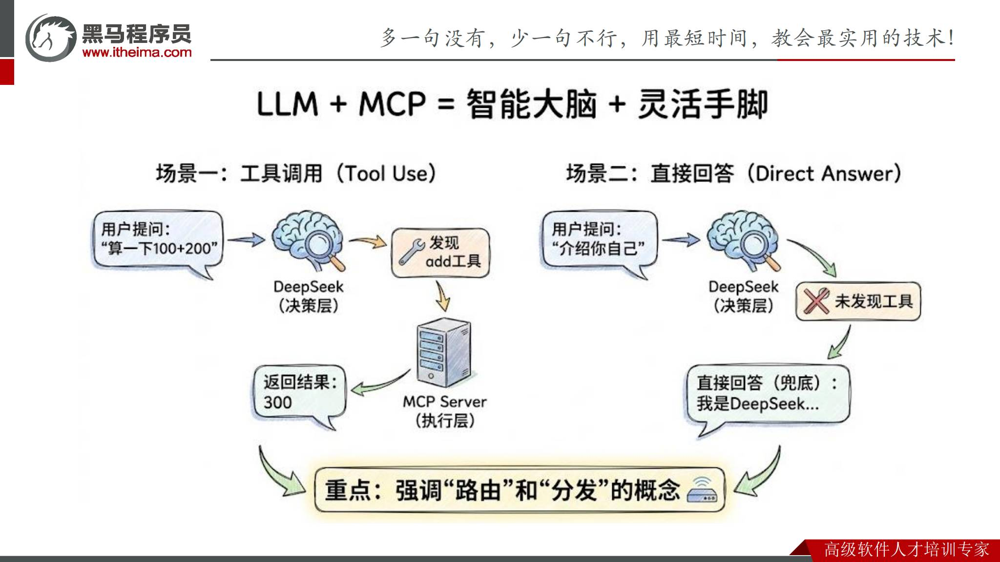

*原课件第35页：应用需要路由与分发，不能把所有文字都发给工具。*

完整交互需要应用组织以下步骤：

1. 从MCP Server发现工具，把名称、说明和参数schema转换成模型接口的工具格式。
2. 将用户问题和工具定义发给支持工具调用的模型。
3. 若模型返回普通回答，直接使用该文本；若返回工具调用，解析名称和JSON参数。
4. 应用核对工具是否可用，调用MCP Client，将工具结果按调用ID回填对话。
5. 再请模型根据结果回答，必要时继续下一轮，不能在第一次工具调用后就假定交互结束。

**工程补充：**下面将固定版本的MCP工具映射为Chat Completions函数工具格式。它属于应用层适配，不是MCP协议要求所有模型都使用相同JSON结构。

```python
def as_model_tools(tools):
    return [
        {
            'type': 'function',
            'function': {
                'name': tool.name,
                'description': tool.description or '',
                'parameters': tool.inputSchema,
            },
        }
        for tool in tools
    ]
```

模型返回`{"name":"add","arguments":"{\"a\":100,\"b\":200}"}`一类调用信息，不是Python源码。不能对模型输出使用`eval()`；参数解析后仍交给服务器进行类型与业务检查。

工具调用请求和MCP Client调用并不是同一层接口。只发一个普通`messages`请求，却未提供工具、未执行调用、未回传结果，模型不会自动完成这条链路。


## 15. 补充示例：模型与MCP之间的对话循环

以下为对第35页路由流程的**工程补充**。在`~/ai_robot_lab/chat_with_tools.py`中，先放入上一节的`as_model_tools()`，再追加下列代码：

```python
import asyncio
import json
import os
import sys

from fastmcp import Client
from openai import AsyncOpenAI


async def run_dialog(llm, mcp_client, user_text, max_rounds=6):
    tools = await mcp_client.list_tools()
    allowed = {tool.name for tool in tools}
    definitions = as_model_tools(tools)
    messages = [
        {'role': 'system', 'content':
         '根据用户请求回答或调用提供的工具。参数不明确时先询问。'
         '描述操作结果时以工具实际返回状态为准。'},
        {'role': 'user', 'content': user_text},
    ]
    for _ in range(max_rounds):
        request = {
            'model': os.environ.get('LLM_MODEL', 'deepseek-chat'),
            'messages': messages,
        }
        if definitions:
            request['tools'] = definitions
            request['tool_choice'] = 'auto'
        response = await llm.chat.completions.create(**request)
        message = response.choices[0].message
        if not message.tool_calls:
            return message.content or ''
        messages.append(message.model_dump(exclude_none=True))
        for call in message.tool_calls:
            try:
                name = call.function.name
                if name not in allowed:
                    raise ValueError('Tool is not in the discovered catalog')
                arguments = json.loads(call.function.arguments)
                if not isinstance(arguments, dict):
                    raise ValueError('Tool arguments must be a JSON object')
                result = await mcp_client.call_tool(name, arguments, timeout=10.0)
                payload = {
                    'ok': not result.is_error,
                    'result': result.data,
                    'content': [part.model_dump(mode='json') for part in result.content],
                }
            except Exception as error:
                payload = {'ok': False, 'error': str(error)}
            messages.append({
                'role': 'tool',
                'tool_call_id': call.id,
                'content': json.dumps(payload, ensure_ascii=False),
            })
    raise RuntimeError('Tool dialogue exceeded its round limit')


async def main():
    question = ' '.join(sys.argv[1:]) or '请计算100加200'
    async with AsyncOpenAI(
        api_key=os.environ['DEEPSEEK_API_KEY'],
        base_url='https://api.deepseek.com',
        timeout=30.0,
    ) as llm:
        async with Client('http://127.0.0.1:8000/mcp') as mcp_client:
            print(await run_dialog(llm, mcp_client, question))


if __name__ == '__main__':
    asyncio.run(main())
```

保持算术Server运行，确认环境变量中的凭据与模型可用，再执行：

```bash
cd ~/ai_robot_lab
.venv/bin/python chat_with_tools.py '请计算100加200'
```

预期在模型选择调用工具时，先得到工具结果，再生成回答；不是仅观察最终文本“300”就能证明发生了工具调用。应同时查看Server日志或记录调用名称、参数和返回值。

示例串行处理一次回答中的调用，限制最多6次模型请求，并把工具失败回传模型。它未实现完整会话存储或流式对话；若模型/服务商不支持此工具格式，应先解决接口兼容问题。

这里没有把自然语言变成任意系统命令；它只可请求Server实际提供的工具。换成机械臂时，服务器还要明确单位、方向、范围与执行状态。


## 16. 从算术Server到机械臂工具接口

课件第33、36—38页将外部能力换成机械臂：先列出扭腰、点头、抬头等动作，再给出腰部与夹爪的参数范围。

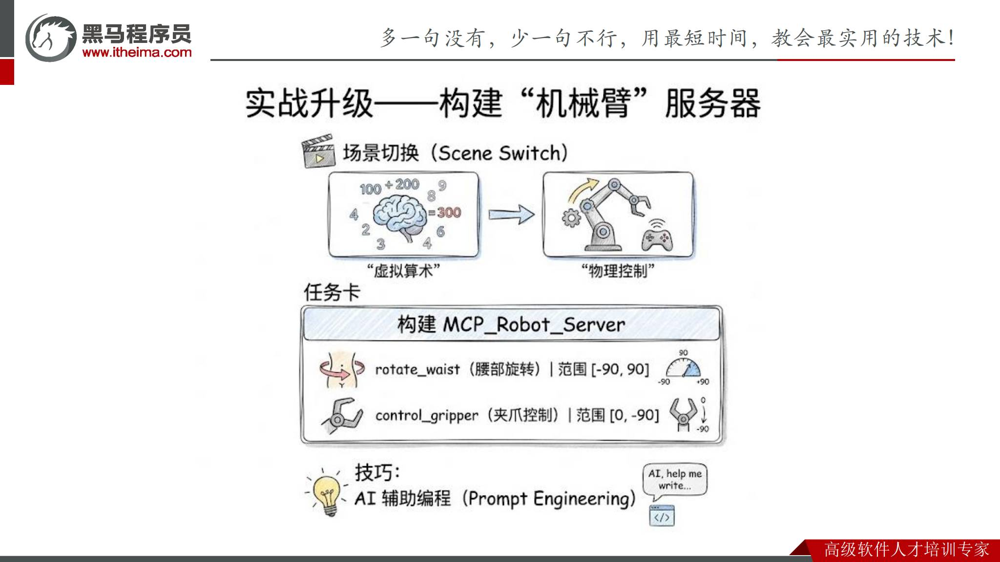

*原课件第36页：rotate_waist范围为-90到90，control_gripper图中写作0到-90。*

本篇把图中的夹爪范围规范写为`[-90, 0]`，表示包含两个端点的同一数值区间。角度使用度；这不是所有机械臂的通用限位。

“向左扭一下”还缺少转多少、绝对目标还是相对增量等信息。第37页展示语义解析，不代表模型可以可靠猜出任意设备的正方向。本篇补充工具采用**绝对目标角**，明确“正值向左、负值向右”的教学约定；实际设备必须依据驱动与零位标定重新核对。

下面为**纯模拟工程补充**。保存`robot_server.py`，先停止算术`server.py`再运行，避免8000端口冲突。此示例没有导入机械臂SDK，也不会连接硬件。

```python
import math
from fastmcp import FastMCP
from pydantic import StrictFloat, StrictInt

robot = FastMCP('MCP_Robot_Server')


def checked_angle(angle, lower, upper):
    if isinstance(angle, bool) or not isinstance(angle, (int, float)):
        raise ValueError('Angle must be a number in degrees')
    value = float(angle)
    if not math.isfinite(value) or not lower <= value <= upper:
        raise ValueError(f'Angle must be finite and in [{lower}, {upper}]')
    return value


@robot.tool()
def rotate_waist(angle: StrictInt | StrictFloat) -> dict:
    """模拟腰部绝对角：单位度，[-90,90]；正值向左，负值向右，不驱动硬件。"""
    value = checked_angle(angle, -90.0, 90.0)
    return {'status': 'simulated', 'joint': 'waist', 'target_deg': value}


@robot.tool()
def control_gripper(angle: StrictInt | StrictFloat) -> dict:
    """模拟夹爪绝对角：单位度，[-90,0]；不驱动硬件，开合含义由设备定义。"""
    value = checked_angle(angle, -90.0, 0.0)
    return {'status': 'simulated', 'joint': 'gripper', 'target_deg': value}


if __name__ == '__main__':
    robot.run(transport='http', host='127.0.0.1', port=8000)
```

```bash
.venv/bin/python robot_server.py
```

可在Client中手动调用`rotate_waist`，传入`{'angle': -45}`，预期返回`status=simulated`与`target_deg=-45.0`。越界、非有限值与非数值输入应失败。先验证明确数字输入，再测试自然语言。

课件第38页的日志说明发出了`rotate_waist`和`control_gripper`调用，不能仅凭日志断定物理动作完成。真实接入时，Server需要把角度交给已验证的驱动，处理设备响应、状态与失败；度转弧度也必须在约定边界完成，不能把这些责任交给语言模型猜测。


## 17. ROS集成：MCP-to-Topic桥接

课件第39—40页将MCP接入ROS：自然语言由Agent处理，MCP Server把工具参数转换成ROS消息，执行节点订阅消息后调用已有控制器。

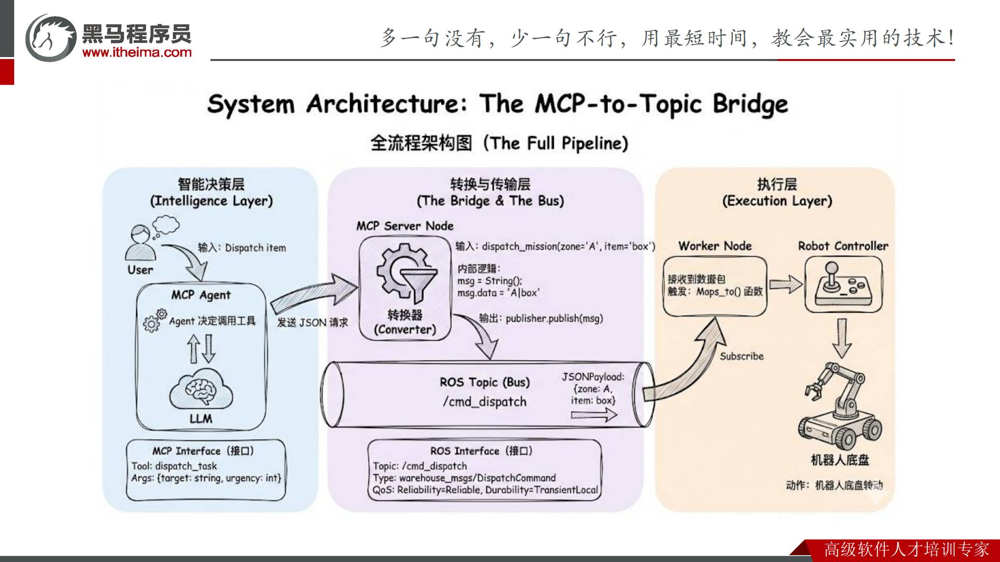

*原课件第40页：决策层 → MCP桥接与ROS Topic → 执行节点。图中部分接口标签并不一致，下文分别说明。*

第40页混用了以下几种接口：

| 图中位置 | 写法 |
|---|---|
| MCP接口标签 | `dispatch_task(target, urgency)` |
| 转换器输入 | `dispatch_mission(zone='A', item='box')` |
| 转换器内部 | `String()`，`msg.data='A|box'` |
| 总线文字 | JSON形式的`zone`与`item` |
| ROS接口标签 | `warehouse_msgs/DispatchCommand` |
| QoS标签 | Reliable、TransientLocal |

**课件差异说明：**这些可以分别作为设计方案，不能当成一套字段和类型完全匹配的实现。下文补充示例统一为`dispatch_mission(zone, item)`，使用`std_msgs/msg/String`承载JSON，话题仍为`/cmd_dispatch`；没有声称课件已提供`warehouse_msgs`的消息文件。

对一次性动作命令，保留旧数据会影响后来加入的订阅者。示例明确选择Reliable与Volatile，避免新执行节点直接接到历史缓存命令；若使用课件的TransientLocal，需要进一步定义旧命令是否应重放。

`publish()`只说明本地发布调用已执行，不代表订阅者已接收、控制器已接受或机器人已完成任务。Topic本身没有请求—完成应答语义。工具返回应如实说明当前阶段。


## 18. 补充示例：发布调度请求并用ROS验证

以下为第40页桥接图的**工程补充**，只在ROS中发布和观察数据。`zone`限定为A/B/C，`item`限定为box/ball；这些是为了让示例接口明确而设定的教学枚举。

先在Ubuntu准备能够读取ROS系统包的独立环境。与前面的纯Python环境不同，这里必须使用Ubuntu的系统Python并开放其系统包路径：

```bash
source /opt/ros/jazzy/setup.bash
cd ~/ai_robot_lab
uv venv --python /usr/bin/python3 --system-site-packages .ros-venv
uv pip install --python .ros-venv/bin/python fastmcp==2.14.7
.ros-venv/bin/python -c 'import rclpy; from std_msgs.msg import String; import fastmcp'
```

保存`bridge_server.py`，停止此前占用8000端口的示例Server后启动：

```python
import json
import uuid

import rclpy
from rclpy.node import Node
from rclpy.qos import QoSProfile, ReliabilityPolicy, DurabilityPolicy
from std_msgs.msg import String
from fastmcp import FastMCP


def make_dispatch(zone, item):
    if zone not in ('A', 'B', 'C'):
        raise ValueError('zone must be A, B or C')
    if item not in ('box', 'ball'):
        raise ValueError('item must be box or ball')
    return {'command_id': uuid.uuid4().hex, 'zone': zone, 'item': item}


def main():
    rclpy.init()
    node = Node('mcp_dispatch_bridge')
    qos = QoSProfile(
        depth=10,
        reliability=ReliabilityPolicy.RELIABLE,
        durability=DurabilityPolicy.VOLATILE,
    )
    publisher = node.create_publisher(String, '/cmd_dispatch', qos)
    mcp = FastMCP('ROS_Dispatch_Server')

    @mcp.tool()
    async def dispatch_mission(zone: str, item: str) -> dict:
        """发布调度请求：zone为A/B/C，item为box/ball；返回发布状态，不代表完成。"""
        payload = make_dispatch(zone, item)
        if publisher.get_subscription_count() == 0:
            raise RuntimeError('No discovered subscriber; request was not published')
        message = String()
        message.data = json.dumps(payload, ensure_ascii=False)
        publisher.publish(message)
        return {'status': 'published', 'command_id': payload['command_id']}

    try:
        mcp.run(transport='http', host='127.0.0.1', port=8000)
    finally:
        node.destroy_node()
        if rclpy.ok():
            rclpy.shutdown()


if __name__ == '__main__':
    main()
```

```bash
source /opt/ros/jazzy/setup.bash
cd ~/ai_robot_lab
.ros-venv/bin/python bridge_server.py
```

此节点只有发布者，没有ROS订阅回调、定时器或Service回调，因此示例不需要执行器处理这些回调。以后增加状态反馈订阅时，必须安排`spin()`与MCP异步服务协作，不能让一个阻塞循环饿死另一个。

另开终端先建立观察订阅：

```bash
source /opt/ros/jazzy/setup.bash
ros2 topic echo /cmd_dispatch std_msgs/msg/String
```

再在第三个终端保存并运行`bridge_client.py`：

```python
import asyncio
from fastmcp import Client


async def main():
    async with Client('http://127.0.0.1:8000/mcp') as client:
        result = await client.call_tool(
            'dispatch_mission', {'zone': 'A', 'item': 'box'})
        print(result.data)


if __name__ == '__main__':
    asyncio.run(main())
```

```bash
cd ~/ai_robot_lab
.venv/bin/python bridge_client.py
```

预期`echo`看到含`command_id`、`zone`、`item`的JSON字符串，Client得到`status=published`。ROS发现尚未完成时可能暂报没有订阅者，确认观察订阅已建立再重试。可用`ros2 topic info /cmd_dispatch --verbose`核对类型、两端QoS与端点数量。

这里`echo`就是观察订阅者，它不会驱动机器人。`get_subscription_count()`只检查发现的订阅端存在，不证明对端是业务执行器，也不证明这次消息送达。真实Worker还需解析JSON、核对请求、调用控制器并提供状态反馈。

`command_id`用于后续关联状态，不会仅凭生成了ID就自动实现去重；重试产生的新ID也无法识别“同一用户动作”。尤其在返回超时时，不能把“没收到结果”直接解释为“动作肯定没发生”。


## 19. 按原课顺序联调与核对

把本篇接成完整系统时，沿用课件“连接 → 发现 → 调用 → 反馈”的思路，逐层增加模块：

1. 录制并回听`output.wav`，确认设备、采样率、位深、声道与时长。
2. 用同一文件验证Whisper，先确认文字转写，再加入在线模型。
3. 分别验证本地与在线TTS，确认合成文件与声音播放都正确。
4. 直接调用MCP算术工具，观察9和20等可确定结果，再加入LLM路由。
5. 对模拟机械臂发送明确角度，核对范围、单位与`simulated`状态，再尝试自然语言。
6. 用ROS `echo`验证桥接数据，最后才由已验证的执行节点接入真实控制器。

| 现象 | 优先检查 |
|---|---|
| 找不到`pyaudio`或安装失败 | 当前解释器、PortAudio开发依赖、包架构 |
| 有WAV却没有声音 | 输入设备、权限、虚拟机转交、回听结果 |
| Whisper解码或Half报错 | FFmpeg、设备/精度设置、`fp16=False` |
| TTS生成了MP3却不发声 | 是否实际调用播放器、输出设备是否正确 |
| 模型鉴权或模型名错误 | 服务商、凭据、Base URL、实际可用模型 |
| MCP连接不上 | Server是否运行、HTTP/stdio是否一致、`/mcp`路径与端口 |
| 工具可见却调用失败 | 参数schema、类型、范围与Server错误 |
| 模型回答了数字但没有调用日志 | 是否提供工具定义、返回的是文本还是tool calls |
| 工具结果回不到模型 | `tool_call_id`是否匹配、是否回填工具消息并继续请求 |
| ROS没有收到调度数据 | 环境、类型、话题、发现过程与QoS |
| 收到`published`却没有动作 | 是否存在真正Worker、是否有控制器接受与完成反馈 |

课件第30、34、38页的磁盘查询、智能灯和智能家居拓展，都可以复用同一条工具链；变化的是工具描述、参数与后端实现。

本篇写作校验包括Notebook结构、图片附件、Python语法，以及固定版本的本地MCP工具发现、调用与参数边界验证。对话循环使用模拟模型响应检查路由和结果回填，没有发送付费模型请求。录音、ASR/TTS、ROS与硬件步骤提供复现方法和预期结果，不作为已在当前电脑完成的实验记录。

到这里，六篇课程从ROS基础、环境、节点与通信，推进到视觉与运动学，再接入语音、语言模型和MCP。最终的职责关系是：**语言模块理解请求，工具层提供明确能力，ROS组织数据与任务，控制器和驱动执行动作，反馈说明实际结果。**
